In [7]:
import os
import shutil
import numpy as np
import pandas as pd
from google.colab import files

os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)
os.makedirs("reports", exist_ok=True)

uploaded = files.upload()  # Select raw_dataset.csv from your desktop

# Save raw copy locally in Colab
shutil.copy("raw_dataset.csv", "data/raw/raw_dataset.csv")

df = pd.read_csv("data/raw/raw_dataset.csv")
df.columns = df.columns.str.strip().str.lower()

print("Shape (rows, columns):", df.shape)
print("\nColumns:", list(df.columns))
print("\nMissing values (%):\n", (df.isnull().sum() / len(df) * 100).round(2))
print("\nDuplicate rows:", df.duplicated().sum())
df.head()

Saving raw_dataset.csv to raw_dataset (1).csv
Shape (rows, columns): (891, 12)

Columns: ['passengerid', 'survived', 'pclass', 'name', 'sex', 'age', 'sibsp', 'parch', 'ticket', 'fare', 'cabin', 'embarked']

Missing values (%):
 passengerid     0.00
survived        0.00
pclass          0.00
name            0.00
sex             0.00
age            19.87
sibsp           0.00
parch           0.00
ticket          0.00
fare            0.00
cabin          77.10
embarked        0.22
dtype: float64

Duplicate rows: 0


,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [8]:
clean_df = df.drop_duplicates().copy()

candidate_cols = ["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
available_cols = [col for col in candidate_cols if col in clean_df.columns]
clean_df = clean_df[available_cols].copy()

# Impute missing numeric features with median
for col in clean_df.select_dtypes(include=[np.number]).columns:
    if col != "survived" and clean_df[col].isnull().any():
        clean_df[col] = clean_df[col].fillna(clean_df[col].median())

# Impute missing categorical/text features with mode
for col in clean_df.select_dtypes(include=["object", "category", "string"]).columns:
    if clean_df[col].isnull().any():
        clean_df[col] = clean_df[col].fillna(clean_df[col].mode()[0])

print("Remaining missing values:\n", clean_df.isnull().sum())

clean_df.to_csv("data/processed/cleaned_dataset.csv", index=False)
print("\nSaved cleaned dataset to data/processed/cleaned_dataset.csv")
clean_df.head()

Remaining missing values:
 survived    0
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64

Saved cleaned dataset to data/processed/cleaned_dataset.csv


,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


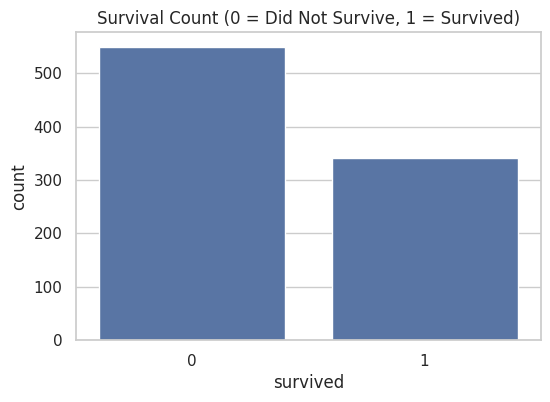

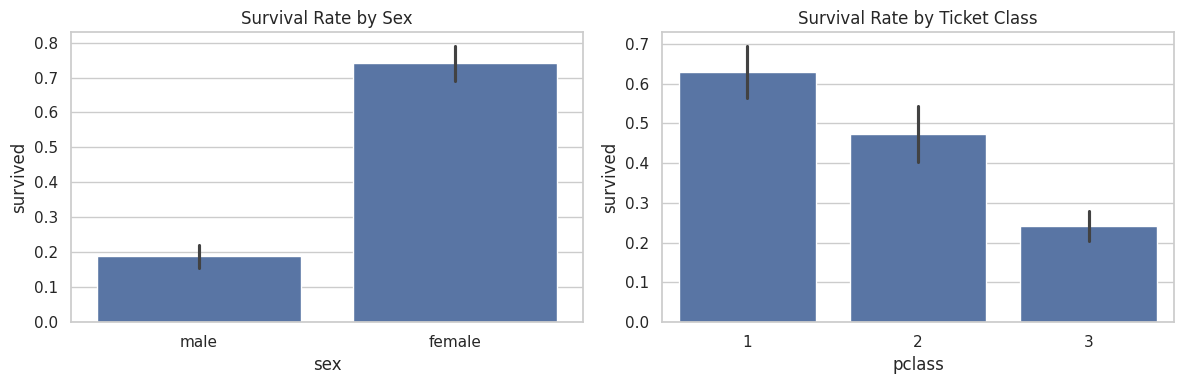

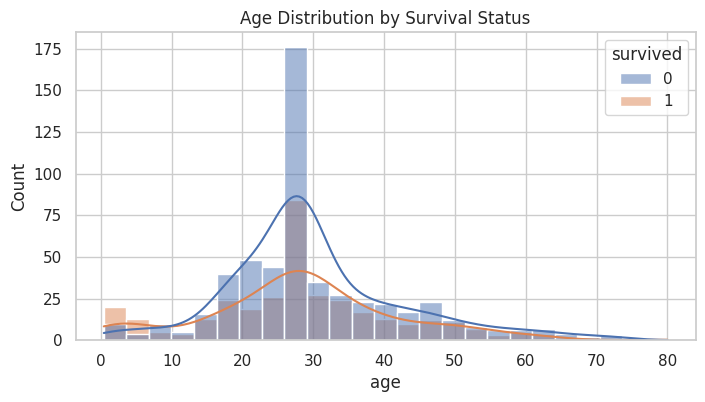

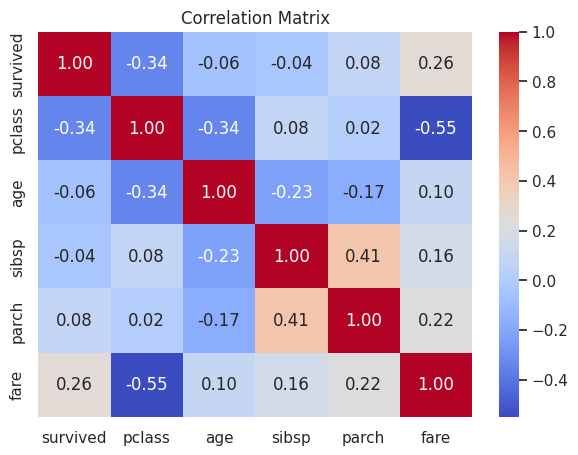

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Target count
plt.figure(figsize=(6, 4))
sns.countplot(data=clean_df, x="survived")
plt.title("Survival Count (0 = Did Not Survive, 1 = Survived)")
plt.show()

# 2. Survival by Sex and Ticket Class
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

if "sex" in clean_df.columns:
    sns.barplot(data=clean_df, x="sex", y="survived", ax=axes[0])
    axes[0].set_title("Survival Rate by Sex")

if "pclass" in clean_df.columns:
    sns.barplot(data=clean_df, x="pclass", y="survived", ax=axes[1])
    axes[1].set_title("Survival Rate by Ticket Class")

plt.tight_layout()
plt.show()

# 3. Age distribution by survival
if "age" in clean_df.columns:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=clean_df, x="age", hue="survived", kde=True, bins=25)
    plt.title("Age Distribution by Survival Status")
    plt.show()

# 4. Correlation heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(clean_df.select_dtypes(include=[np.number]).corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

                         Model  Accuracy  Precision  Recall  F1-Score
Logistic Regression (Baseline)    0.8045     0.7931  0.6667    0.7244
                 Random Forest    0.8156     0.7812  0.7246    0.7519


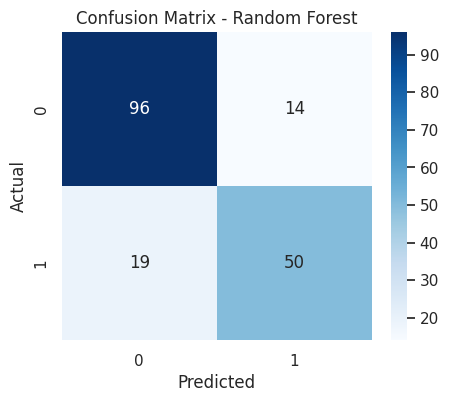

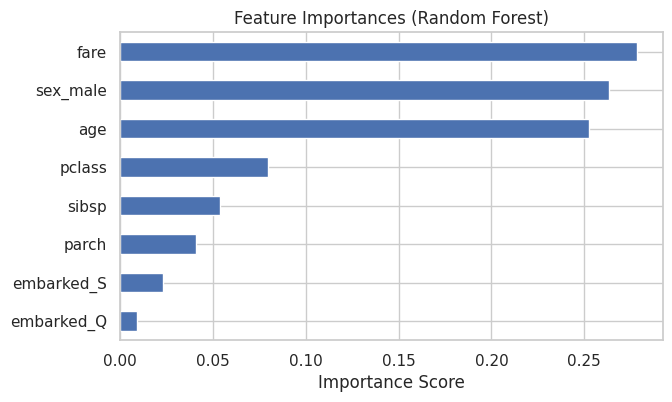

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

cat_cols = [c for c in ["sex", "embarked"] if c in clean_df.columns]
model_df = pd.get_dummies(clean_df, columns=cat_cols, drop_first=True)

X = model_df.drop(columns=["survived"])
y = model_df["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

def evaluate_model(name, model):
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    return {
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, preds), 4),
        "Precision": round(precision_score(y_test, preds), 4),
        "Recall": round(recall_score(y_test, preds), 4),
        "F1-Score": round(f1_score(y_test, preds), 4),
    }, preds

log_metrics, _ = evaluate_model(
    "Logistic Regression (Baseline)",
    LogisticRegression(max_iter=1000, random_state=42)
)
rf_metrics, rf_preds = evaluate_model(
    "Random Forest",
    RandomForestClassifier(n_estimators=100, random_state=42)
)

results_df = pd.DataFrame([log_metrics, rf_metrics])
print(results_df.to_string(index=False))

# Confusion matrix for Random Forest
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, rf_preds), annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Feature importance from Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=True)
plt.figure(figsize=(7, 4))
importances.plot(kind="barh")
plt.title("Feature Importances (Random Forest)")
plt.xlabel("Importance Score")
plt.show()

In [11]:
report_text = """# Titanic Survival Prediction — Project Report

## 1. Problem
Predict passenger survival (`survived`) from `raw_dataset.csv` using passenger demographics and ticket features, and identify which factors were most associated with survival.

## 2. Approach
- **Data Cleaning:** Loaded `raw_dataset.csv`, removed duplicates, selected core features, filled missing numeric values with the median and missing categorical values with the mode, and exported `data/processed/cleaned_dataset.csv`.
- **EDA:** Inspected target balance, survival rates by sex and passenger class, age distribution, and numeric correlations.
- **Modeling & Evaluation:** Applied one-hot encoding, split data 80/20 with stratification (`random_state=42`), and compared **Logistic Regression** (baseline) against **Random Forest** using Accuracy, Precision, Recall, and F1-Score.

## 3. Results
| Model | Accuracy | Precision | Recall | F1-Score |
| --- | --- | --- | --- | --- |
| Logistic Regression (Baseline) | *(paste from Cell 4)* | *(paste)* | *(paste)* | *(paste)* |
| Random Forest | *(paste from Cell 4)* | *(paste)* | *(paste)* | *(paste)* |

## 4. Insights & Limitations
- **Key Insights:** Sex, ticket class (`pclass`), and fare strongly relate to survival rates.
- **Limitations & Next Steps:** Limited set of engineered features; cross-validation and hyperparameter tuning are good next steps.
"""

with open("reports/project_report.md", "w") as f:
    f.write(report_text)

# Download cleaned CSV and report straight to your computer
files.download("data/processed/cleaned_dataset.csv")
files.download("reports/project_report.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>